# CS-4063 — Natural Language Processing
## Assignment 3: Transformer-based Review Understanding with RAG-Enhanced Explanation Generation

## Imports and Setup

In [1]:
import os, gzip, json, math, random, re, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import classification_report, f1_score
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')


Using device: cuda


## 1. Dataset Loading and Preprocessing

In [2]:
DATA_FILES = {
    'beauty':      'data/beauty.json.gz',
    'cellphones':  'data/cellphones.json.gz',
    'electronics': 'data/electronics.json.gz',
    'home':        'data/home.json.gz',
    'sports':      'data/sports.json.gz',
}
SELECTED_CATEGORIES = ['sports', 'cellphones', 'electronics']
REVIEWS_PER_CATEGORY = 12000   
MAX_SEQ_LEN = 128
MIN_FREQ    = 3                

def load_amazon_reviews(filepath, category, max_reviews=12000):
    """Load Amazon review JSON.gz file and extract text + rating."""
    reviews = []
    with gzip.open(filepath, 'rt', encoding='utf-8', errors='ignore') as f:
        for i, line in enumerate(f):
            if i >= max_reviews * 3:   # read extra to allow filtering
                break
            try:
                obj = json.loads(line.strip())
                text   = obj.get('reviewText', '') or obj.get('summary', '')
                rating = obj.get('overall', None)
                if text and rating and len(text.split()) >= 5:
                    reviews.append({
                        'text': text,
                        'rating': int(float(rating)),
                        'category': category
                    })
                    if len(reviews) >= max_reviews:
                        break
            except Exception:
                continue
    return reviews

print('Loading dataset...')
all_reviews = []
for cat in SELECTED_CATEGORIES:
    path = DATA_FILES[cat]
    if os.path.exists(path):
        reviews = load_amazon_reviews(path, cat, REVIEWS_PER_CATEGORY)
        print(f'  {cat}: loaded {len(reviews)} reviews')
        all_reviews.extend(reviews)
    else:
        print(f'  WARNING: {path} not found — skipping {cat}')

print(f'Total reviews loaded: {len(all_reviews)}')
df = pd.DataFrame(all_reviews)
print(df['rating'].value_counts().sort_index())

Loading dataset...
  sports: loaded 12000 reviews
  cellphones: loaded 12000 reviews
  electronics: loaded 12000 reviews
Total reviews loaded: 36000
rating
1     2102
2     1751
3     3212
4     7430
5    21505
Name: count, dtype: int64


In [3]:
def clean_text(text):
    """Text cleaning: lowercase, remove HTML, punctuation normalisation."""
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)           # strip HTML tags
    text = re.sub(r'http\S+|www\.\S+', ' ', text)  # strip URLs
    text = re.sub(r'[^a-z0-9\s\'\-]', ' ', text)  # keep letters/digits/apostrophe/hyphen
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize(text):
    """Simple whitespace tokenizer with basic contraction splitting."""
    text = re.sub(r"(n't|'re|'ve|'ll|'d|'m|'s)", r' \1', text)
    return text.split()

# Apply cleaning
df['clean_text'] = df['text'].apply(clean_text)
df['tokens']     = df['clean_text'].apply(tokenize)

def rating_to_sentiment(r):
    if r <= 2: return 0
    if r == 3: return 1
    return 2
df['sentiment'] = df['rating'].apply(rating_to_sentiment)

def length_category(tokens):
    n = len(tokens)
    if n < 20: return 0
    if n <= 80: return 1
    return 2
df['length_cat'] = df['tokens'].apply(length_category)

print('Sentiment distribution:')
print(df['sentiment'].value_counts().sort_index())
print('\nLength category distribution:')
print(df['length_cat'].value_counts().sort_index())

Sentiment distribution:
sentiment
0     3853
1     3212
2    28935
Name: count, dtype: int64

Length category distribution:
length_cat
0      653
1    21869
2    13478
Name: count, dtype: int64


In [4]:
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(df)
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
train_df = df.iloc[:n_train].reset_index(drop=True)
val_df   = df.iloc[n_train:n_train+n_val].reset_index(drop=True)
test_df  = df.iloc[n_train+n_val:].reset_index(drop=True)
print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')

counter = Counter(token for tokens in train_df['tokens'] for token in tokens)
SPECIAL = ['<PAD>', '<UNK>']
vocab_words = SPECIAL + [w for w, c in counter.most_common() if c >= MIN_FREQ]
word2idx = {w: i for i, w in enumerate(vocab_words)}
idx2word = {i: w for w, i in word2idx.items()}
VOCAB_SIZE = len(vocab_words)
PAD_IDX = word2idx['<PAD>']
UNK_IDX = word2idx['<UNK>']
print(f'Vocabulary size: {VOCAB_SIZE}')

def encode(tokens, max_len=MAX_SEQ_LEN):
    """Convert tokens to padded/truncated index sequence."""
    ids = [word2idx.get(t, UNK_IDX) for t in tokens[:max_len]]
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids

train_df['input_ids'] = train_df['tokens'].apply(encode)
val_df['input_ids']   = val_df['tokens'].apply(encode)
test_df['input_ids']  = test_df['tokens'].apply(encode)

with open('results/vocab.pkl', 'wb') as f:
    pickle.dump({'word2idx': word2idx, 'idx2word': idx2word}, f)
print('Vocabulary saved.')

Train: 25200 | Val: 5400 | Test: 5400
Vocabulary size: 17037
Vocabulary saved.


## Part A — Encoder Model for Understanding

In [5]:
class ReviewDataset(Dataset):
    def __init__(self, df):
        self.input_ids  = torch.tensor(df['input_ids'].tolist(), dtype=torch.long)
        self.sentiment  = torch.tensor(df['sentiment'].tolist(), dtype=torch.long)
        self.length_cat = torch.tensor(df['length_cat'].tolist(), dtype=torch.long)

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.sentiment[idx], self.length_cat[idx]

BATCH_SIZE = 128
train_dataset = ReviewDataset(train_df)
val_dataset   = ReviewDataset(val_df)
test_dataset  = ReviewDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [6]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_k, dropout=0.1):
        super().__init__()
        self.scale   = math.sqrt(d_k)
        self.dropout = nn.Dropout(dropout)

    def forward(self, Q, K, V, mask=None):
        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale 
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn = F.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        return torch.matmul(attn, V), attn  


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_Q = nn.Linear(d_model, d_model, bias=False)
        self.W_K = nn.Linear(d_model, d_model, bias=False)
        self.W_V = nn.Linear(d_model, d_model, bias=False)
        self.W_O = nn.Linear(d_model, d_model, bias=False)

        self.attention = ScaledDotProductAttention(self.d_k, dropout)
        self.dropout   = nn.Dropout(dropout)

    def split_heads(self, x):
        """(B, S, d_model) → (B, H, S, d_k)"""
        B, S, _ = x.size()
        return x.view(B, S, self.num_heads, self.d_k).transpose(1, 2)

    def forward(self, Q, K, V, mask=None):
        B = Q.size(0)
        Q = self.split_heads(self.W_Q(Q))
        K = self.split_heads(self.W_K(K))
        V = self.split_heads(self.W_V(V))

        x, _ = self.attention(Q, K, V, mask)         
        x = x.transpose(1, 2).contiguous().view(B, -1, self.num_heads * self.d_k)  
        return self.W_O(x)


class PositionwiseFFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.linear2(self.dropout(F.gelu(self.linear1(x))))


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0)) 

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class EncoderBlock(nn.Module):
    """Single encoder layer: Multi-head self-attention + FFN + residuals + LayerNorm."""
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn  = MultiHeadAttention(d_model, num_heads, dropout)
        self.ffn        = PositionwiseFFN(d_model, d_ff, dropout)
        self.norm1      = nn.LayerNorm(d_model)
        self.norm2      = nn.LayerNorm(d_model)
        self.dropout    = nn.Dropout(dropout)

    def forward(self, x, src_mask=None):
        attn_out = self.self_attn(x, x, x, src_mask)
        x = self.norm1(x + self.dropout(attn_out))
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        return x


class TransformerEncoder(nn.Module):
    """
    Encoder-only Transformer for multi-task learning:
      Task 1: Sentiment classification (3 classes)
      Task 2: Review length category (3 classes)
    Also produces a fixed-dimensional embedding vector per review.
    """
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=3,
                 d_ff=256, max_seq_len=MAX_SEQ_LEN, dropout=0.1,
                 pad_idx=PAD_IDX, num_sentiment=3, num_length_cat=3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc   = PositionalEncoding(d_model, max_len=max_seq_len+10, dropout=dropout)
        self.layers    = nn.ModuleList([
            EncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.pool_norm = nn.LayerNorm(d_model)
        self.sentiment_head  = nn.Linear(d_model, num_sentiment)
        self.length_cat_head = nn.Linear(d_model, num_length_cat)
        self.pad_idx = pad_idx

    def make_src_mask(self, src):
        """Padding mask: (B,1,1,S) — zeros on PAD positions."""
        return (src != self.pad_idx).unsqueeze(1).unsqueeze(2)

    def encode(self, src):
        """Run encoder and return CLS-like pooled representation."""
        mask = self.make_src_mask(src) 
        x = self.embedding(src)        
        x = self.pos_enc(x)
        for layer in self.layers:
            x = layer(x, mask)
        valid = (src != self.pad_idx).float().unsqueeze(-1)  
        pooled = (x * valid).sum(1) / valid.sum(1).clamp(min=1e-9) 
        return self.pool_norm(pooled)

    def forward(self, src):
        rep = self.encode(src)  
        sent_logits   = self.sentiment_head(rep)
        length_logits = self.length_cat_head(rep)
        return sent_logits, length_logits, rep

In [7]:
# ── Encoder Hyperparameters ────────────────────────────────────────────────
ENC_D_MODEL    = 128
ENC_NUM_HEADS  = 4
ENC_NUM_LAYERS = 3
ENC_D_FF       = 256
ENC_DROPOUT    = 0.2
ENC_LR         = 3e-4
ENC_EPOCHS     = 15
ENC_SENT_WEIGHT   = 0.7   # weight for sentiment loss in combined loss
ENC_LENGTH_WEIGHT = 0.3   # weight for length-category loss

encoder = TransformerEncoder(
    vocab_size=VOCAB_SIZE,
    d_model=ENC_D_MODEL,
    num_heads=ENC_NUM_HEADS,
    num_layers=ENC_NUM_LAYERS,
    d_ff=ENC_D_FF,
    max_seq_len=MAX_SEQ_LEN,
    dropout=ENC_DROPOUT,
    pad_idx=PAD_IDX
).to(DEVICE)

optimizer_enc = torch.optim.AdamW(encoder.parameters(), lr=ENC_LR, weight_decay=1e-4)
scheduler_enc = torch.optim.lr_scheduler.OneCycleLR(
    optimizer_enc, max_lr=ENC_LR,
    steps_per_epoch=len(train_loader),
    epochs=ENC_EPOCHS
)
criterion_ce = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in encoder.parameters() if p.requires_grad)
print(f'Encoder parameters: {total_params:,}')

Encoder parameters: 2,577,670


In [8]:
def train_encoder_epoch(model, loader, optimizer, scheduler):
    model.train()
    total_loss = 0
    all_sent_preds, all_sent_true   = [], []
    all_len_preds,  all_len_true    = [], []

    for ids, sentiment, length_cat in tqdm(loader, leave=False, desc='Train'):
        ids, sentiment, length_cat = ids.to(DEVICE), sentiment.to(DEVICE), length_cat.to(DEVICE)
        optimizer.zero_grad()
        sent_logits, len_logits, _ = model(ids)

        loss_sent = criterion_ce(sent_logits, sentiment)
        loss_len  = criterion_ce(len_logits,  length_cat)
        loss = ENC_SENT_WEIGHT * loss_sent + ENC_LENGTH_WEIGHT * loss_len

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        all_sent_preds.extend(sent_logits.argmax(1).cpu().tolist())
        all_sent_true.extend(sentiment.cpu().tolist())
        all_len_preds.extend(len_logits.argmax(1).cpu().tolist())
        all_len_true.extend(length_cat.cpu().tolist())

    avg_loss = total_loss / len(loader)
    sent_f1  = f1_score(all_sent_true, all_sent_preds, average='macro', zero_division=0)
    len_f1   = f1_score(all_len_true,  all_len_preds,  average='macro', zero_division=0)
    return avg_loss, sent_f1, len_f1


def eval_encoder(model, loader):
    model.eval()
    total_loss = 0
    all_sent_preds, all_sent_true  = [], []
    all_len_preds,  all_len_true   = [], []

    with torch.no_grad():
        for ids, sentiment, length_cat in loader:
            ids, sentiment, length_cat = ids.to(DEVICE), sentiment.to(DEVICE), length_cat.to(DEVICE)
            sent_logits, len_logits, _ = model(ids)

            loss_sent = criterion_ce(sent_logits, sentiment)
            loss_len  = criterion_ce(len_logits,  length_cat)
            loss = ENC_SENT_WEIGHT * loss_sent + ENC_LENGTH_WEIGHT * loss_len
            total_loss += loss.item()

            all_sent_preds.extend(sent_logits.argmax(1).cpu().tolist())
            all_sent_true.extend(sentiment.cpu().tolist())
            all_len_preds.extend(len_logits.argmax(1).cpu().tolist())
            all_len_true.extend(length_cat.cpu().tolist())

    avg_loss = total_loss / len(loader)
    sent_f1  = f1_score(all_sent_true, all_sent_preds, average='macro', zero_division=0)
    len_f1   = f1_score(all_len_true,  all_len_preds,  average='macro', zero_division=0)
    return avg_loss, sent_f1, len_f1, all_sent_preds, all_sent_true, all_len_preds, all_len_true

In [9]:
enc_history = {'train_loss': [], 'val_loss': [], 'train_sent_f1': [], 'val_sent_f1': [],
               'train_len_f1': [], 'val_len_f1': []}
best_val_sent_f1 = 0

for epoch in range(1, ENC_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_sf1, tr_lf1 = train_encoder_epoch(encoder, train_loader, optimizer_enc, scheduler_enc)
    vl_loss, vl_sf1, vl_lf1, *_ = eval_encoder(encoder, val_loader)
    elapsed = time.time() - t0

    enc_history['train_loss'].append(tr_loss)
    enc_history['val_loss'].append(vl_loss)
    enc_history['train_sent_f1'].append(tr_sf1)
    enc_history['val_sent_f1'].append(vl_sf1)
    enc_history['train_len_f1'].append(tr_lf1)
    enc_history['val_len_f1'].append(vl_lf1)

    print(f'Epoch {epoch:02d}/{ENC_EPOCHS} [{elapsed:.1f}s] '
          f'Loss: {tr_loss:.4f}/{vl_loss:.4f} '
          f'SentF1: {tr_sf1:.3f}/{vl_sf1:.3f} '
          f'LenF1: {tr_lf1:.3f}/{vl_lf1:.3f}')

    if vl_sf1 > best_val_sent_f1:
        best_val_sent_f1 = vl_sf1
        torch.save(encoder.state_dict(), 'models/encoder_best.pt')

print(f'\nBest Val Sentiment F1: {best_val_sent_f1:.4f}')

Epoch 01/15 [17.4s] Loss: 0.6472/0.4785 SentF1: 0.298/0.298 LenF1: 0.501/0.652


Epoch 02/15 [16.5s] Loss: 0.4606/0.4142 SentF1: 0.303/0.337 LenF1: 0.674/0.749


Epoch 03/15 [16.5s] Loss: 0.4164/0.3851 SentF1: 0.357/0.401 LenF1: 0.853/0.919


Epoch 04/15 [16.6s] Loss: 0.3944/0.3691 SentF1: 0.388/0.415 LenF1: 0.918/0.937


Epoch 05/15 [16.6s] Loss: 0.3772/0.3533 SentF1: 0.416/0.462 LenF1: 0.932/0.930


...

Epoch 11/15 [16.8s] Loss: 0.3035/0.3189 SentF1: 0.551/0.522 LenF1: 0.975/0.958


Epoch 12/15 [16.7s] Loss: 0.2972/0.3141 SentF1: 0.554/0.536 LenF1: 0.978/0.960


Epoch 13/15 [16.8s] Loss: 0.2945/0.3164 SentF1: 0.558/0.550 LenF1: 0.981/0.971


Epoch 14/15 [16.7s] Loss: 0.2905/0.3155 SentF1: 0.566/0.549 LenF1: 0.976/0.962


Epoch 15/15 [16.9s] Loss: 0.2876/0.3155 SentF1: 0.570/0.550 LenF1: 0.975/0.965

Best Val Sentiment F1: 0.5508


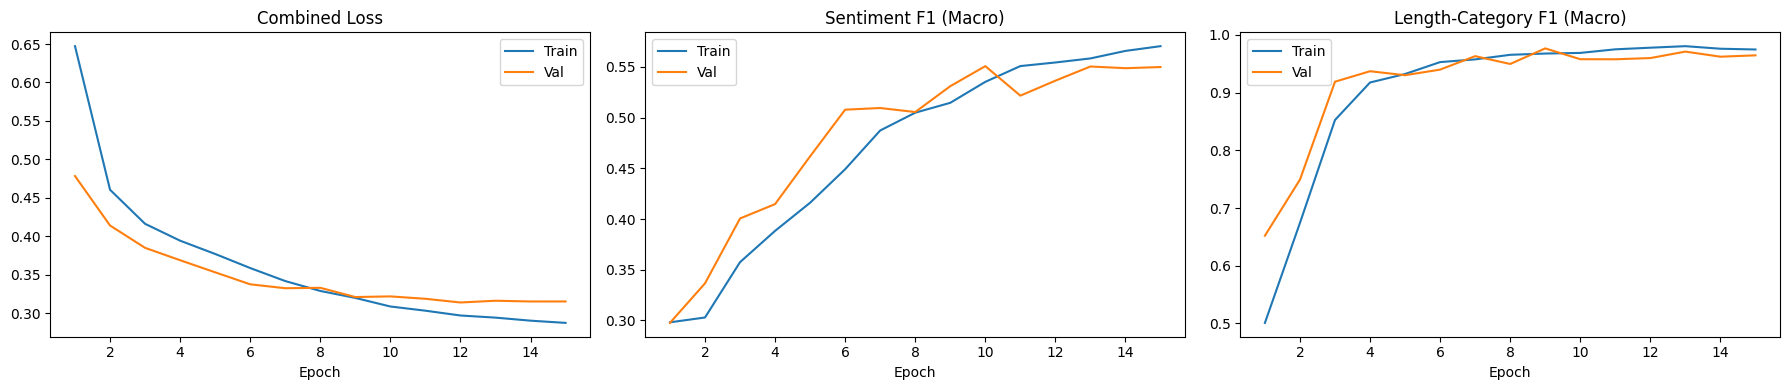

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

epochs = range(1, ENC_EPOCHS + 1)
axes[0].plot(epochs, enc_history['train_loss'], label='Train')
axes[0].plot(epochs, enc_history['val_loss'],   label='Val')
axes[0].set_title('Combined Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(epochs, enc_history['train_sent_f1'], label='Train')
axes[1].plot(epochs, enc_history['val_sent_f1'],   label='Val')
axes[1].set_title('Sentiment F1 (Macro)'); axes[1].set_xlabel('Epoch'); axes[1].legend()

axes[2].plot(epochs, enc_history['train_len_f1'], label='Train')
axes[2].plot(epochs, enc_history['val_len_f1'],   label='Val')
axes[2].set_title('Length-Category F1 (Macro)'); axes[2].set_xlabel('Epoch'); axes[2].legend()

plt.tight_layout()
plt.savefig('results/encoder_learning_curves.png', dpi=150)
plt.show()

In [11]:
encoder.load_state_dict(torch.load('models/encoder_best.pt', map_location=DEVICE))
_, _, _, sp, st, lp, lt = eval_encoder(encoder, test_loader)

print('=== Sentiment Classification (Test Set) ===')
print(classification_report(st, sp, target_names=['Negative','Neutral','Positive']))
print('=== Length-Category Classification (Test Set) ===')
print(classification_report(lt, lp, target_names=['Short','Medium','Long']))

=== Sentiment Classification (Test Set) ===
              precision    recall  f1-score   support

    Negative       0.54      0.48      0.51       548
     Neutral       0.31      0.15      0.20       463
    Positive       0.88      0.94      0.91      4389

    accuracy                           0.83      5400
   macro avg       0.58      0.52      0.54      5400
weighted avg       0.80      0.83      0.81      5400

=== Length-Category Classification (Test Set) ===
              precision    recall  f1-score   support

       Short       0.96      0.80      0.87        88
      Medium       0.99      0.99      0.99      3281
        Long       0.99      1.00      0.99      2031

    accuracy                           0.99      5400
   macro avg       0.98      0.93      0.95      5400
weighted avg       0.99      0.99      0.99      5400



In [12]:
print('Generating and saving training embeddings...')
encoder.eval()
all_train_embeddings = []

embed_loader = DataLoader(train_dataset, batch_size=256, shuffle=False)
with torch.no_grad():
    for ids, _, _ in tqdm(embed_loader, desc='Encoding train set'):
        ids = ids.to(DEVICE)
        _, _, rep = encoder(ids)
        all_train_embeddings.append(rep.cpu().numpy())

train_embeddings = np.vstack(all_train_embeddings) 
np.save('results/train_embeddings.npy', train_embeddings)
print(f'Saved embeddings shape: {train_embeddings.shape}')

Generating and saving training embeddings...


Encoding train set: 100%|██████████| 99/99 [00:05<00:00, 19.72it/s]

Saved embeddings shape: (25200, 128)


## Part B — Retrieval Module

In [13]:
train_embeddings = np.load('results/train_embeddings.npy')

norms = np.linalg.norm(train_embeddings, axis=1, keepdims=True)
train_embeddings_norm = train_embeddings / (norms + 1e-9)

def retrieve_top_k(query_embedding, train_embs_norm, k=3):
    """
    Cosine similarity retrieval.
    Returns indices of top-k most similar training examples.
    """
    q_norm = query_embedding / (np.linalg.norm(query_embedding) + 1e-9)
    sims   = train_embs_norm @ q_norm          # (N_train,)
    top_k  = np.argsort(sims)[::-1][:k]
    return top_k, sims[top_k]

def get_query_embedding(model, input_ids_tensor):
    """Get encoder embedding for a single/batch of reviews."""
    model.eval()
    with torch.no_grad():
        inp = input_ids_tensor.unsqueeze(0).to(DEVICE) if input_ids_tensor.dim() == 1 else input_ids_tensor.to(DEVICE)
        _, _, rep = model(inp)
    return rep.cpu().numpy()

K = 3   # configurable — 3 balances relevance vs diversity
print(f'Retrieval module ready. Using top-k = {K}')

Retrieval module ready. Using top-k = 3


In [14]:
LABEL_MAP = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
LEN_MAP   = {0: 'Short', 1: 'Medium', 2: 'Long'}

print('=== Retrieval Quality Examples ===')
for sample_idx in range(5):
    query_ids  = test_dataset.input_ids[sample_idx]
    query_emb  = get_query_embedding(encoder, query_ids)
    top_k_idx, scores = retrieve_top_k(query_emb[0], train_embeddings_norm, k=K)

    print(f'\n--- Query #{sample_idx+1} ---')
    print(f'  Text   : {test_df.iloc[sample_idx]["clean_text"][:120]}...')
    print(f'  Sentiment: {LABEL_MAP[test_df.iloc[sample_idx]["sentiment"]]}')
    for rank, (idx, sim) in enumerate(zip(top_k_idx, scores)):
        print(f'  Retrieved #{rank+1} (sim={sim:.3f}): [{LABEL_MAP[train_df.iloc[idx]["sentiment"]]}] '
              f'{train_df.iloc[idx]["clean_text"][:100]}...')

=== Retrieval Quality Examples ===

--- Query #1 ---
  Text   : great case the green color is shimmery metallic i wish the button on back of the case was flush but no big deal very nic...
  Sentiment: Positive
  Retrieved #1 (sim=0.916): [Positive] this is a great protector for this garmin gps model vista sometimes i must remove it in order to see...
  Retrieved #2 (sim=0.913): [Positive] great product that deliver good frequency range came with 2 sets of rubber padding one of the super ...
  Retrieved #3 (sim=0.913): [Positive] my bluetooth arrive and i could not wait to try it but of course i have to charge it up first i like...

--- Query #2 ---
  Text   : it works pretty much as described but the problem is that if you ever have to remove the pieces from the wall and move t...
  Sentiment: Positive
  Retrieved #1 (sim=0.962): [Positive] this is my first every bluetooth headset for my cell phone all this time i managed by not picking up...
  Retrieved #2 (sim=0.950): [Negative] i ca

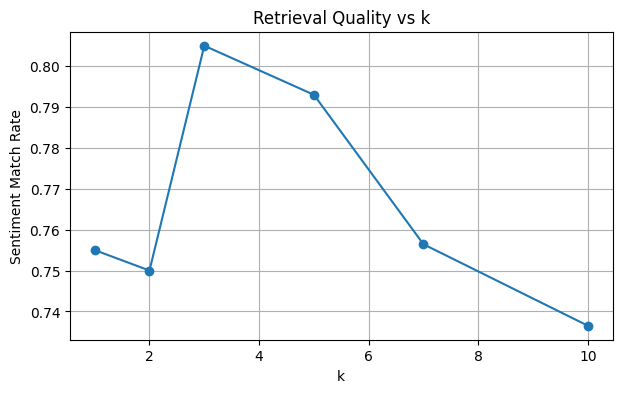

k=1: sentiment match rate = 0.755
k=2: sentiment match rate = 0.750
k=3: sentiment match rate = 0.805
k=5: sentiment match rate = 0.793
k=7: sentiment match rate = 0.756
k=10: sentiment match rate = 0.737


In [15]:
def retrieval_match_rate(model, test_df, train_df, train_embs_norm, k=3, n_samples=200):
    """Fraction of retrieved reviews with same sentiment as query."""
    matches = 0
    total   = 0
    indices = random.sample(range(len(test_df)), min(n_samples, len(test_df)))
    dataset = ReviewDataset(test_df)
    for i in indices:
        q_emb = get_query_embedding(model, dataset.input_ids[i])[0]
        top_k_idx, _ = retrieve_top_k(q_emb, train_embs_norm, k=k)
        query_sent   = test_df.iloc[i]['sentiment']
        for idx in top_k_idx:
            if train_df.iloc[idx]['sentiment'] == query_sent:
                matches += 1
            total += 1
    return matches / total if total > 0 else 0

k_values = [1, 2, 3, 5, 7, 10]
match_rates = [retrieval_match_rate(encoder, test_df, train_df, train_embeddings_norm, k=k)
               for k in k_values]

plt.figure(figsize=(7, 4))
plt.plot(k_values, match_rates, marker='o')
plt.xlabel('k'); plt.ylabel('Sentiment Match Rate')
plt.title('Retrieval Quality vs k')
plt.grid(True)
plt.savefig('results/retrieval_k_analysis.png', dpi=150)
plt.show()

for k, mr in zip(k_values, match_rates):
    print(f'k={k}: sentiment match rate = {mr:.3f}')

## Part C — Decoder Model for Explanation Generation

In [16]:
SPECIAL_DEC = ['<PAD>', '<UNK>', '<BOS>', '<EOS>']

dec_word2idx = dict(word2idx)  # copy
for tok in SPECIAL_DEC:
    if tok not in dec_word2idx:
        dec_word2idx[tok] = len(dec_word2idx)
dec_idx2word = {v: k for k, v in dec_word2idx.items()}
DEC_VOCAB_SIZE = len(dec_word2idx)
BOS_IDX = dec_word2idx['<BOS>']
EOS_IDX = dec_word2idx['<EOS>']
DEC_PAD_IDX = dec_word2idx['<PAD>']

MAX_GEN_LEN = 40   # max explanation length

print(f'Decoder vocab size: {DEC_VOCAB_SIZE}')
print(f'BOS={BOS_IDX}, EOS={EOS_IDX}, PAD={DEC_PAD_IDX}')

Decoder vocab size: 17039
BOS=17037, EOS=17038, PAD=0


In [17]:
SENT_WORDS  = {0: 'negative', 1: 'neutral', 2: 'positive'}
LEN_WORDS   = {0: 'brief', 1: 'moderate', 2: 'detailed'}

def make_reference_explanation(row):
    """Generate a simple template explanation as training target."""
    sent_word = SENT_WORDS[row['sentiment']]
    len_word  = LEN_WORDS[row['length_cat']]
    snippet   = ' '.join(row['tokens'][:10])
    return f"this {len_word} review expresses {sent_word} sentiment about the product"

def make_input_sequence(row, retrieved_rows, k=K):
    """
    Construct decoder input: 
    [BOS] sent_label length_label review_tokens [SEP] retrieved1_tokens [SEP] ...
    Template: <BOS> SENTIMENT LENGTHCAT REVIEW_TEXT <SEP> RETRIEVED_1 ... <EOS>
    """
    sent_tok = f'__sent_{SENT_WORDS[row["sentiment"]]}__'
    len_tok  = f'__len_{LEN_WORDS[row["length_cat"]]}__'
    review_tokens = row['tokens'][:30]
    parts = [sent_tok, len_tok] + review_tokens
    for rrow in retrieved_rows[:k]:
        parts += ['<SEP>'] + rrow['tokens'][:15]
    return parts

# Add special tokens to vocab if needed
for tok in ['<SEP>', '__sent_negative__', '__sent_neutral__', '__sent_positive__',
            '__len_brief__', '__len_moderate__', '__len_detailed__']:
    if tok not in dec_word2idx:
        dec_word2idx[tok] = len(dec_word2idx)
dec_idx2word = {v: k for k, v in dec_word2idx.items()}
DEC_VOCAB_SIZE = len(dec_word2idx)
print(f'Updated decoder vocab size: {DEC_VOCAB_SIZE}')

Updated decoder vocab size: 17046


In [18]:
def build_decoder_data(df_split, split_name, encoder_model, train_df_ref,
                        train_embs_norm, k=K, max_src=80, max_tgt=MAX_GEN_LEN):
    """Build (input_ids, target_ids) pairs with retrieved context."""
    encoder_model.eval()
    temp_dataset = ReviewDataset(df_split)
    src_list, tgt_list = [], []

    for i in tqdm(range(len(df_split)), desc=f'Building {split_name} decoder data'):
        row = df_split.iloc[i]
        # Get query embedding
        q_emb = get_query_embedding(encoder_model, temp_dataset.input_ids[i])[0]
        top_k_idx, _ = retrieve_top_k(q_emb, train_embs_norm, k=k)
        retrieved_rows = [train_df_ref.iloc[idx] for idx in top_k_idx]

        # Input sequence
        input_tokens = make_input_sequence(row, retrieved_rows, k=k)
        src_ids = [BOS_IDX] + [dec_word2idx.get(t, dec_word2idx['<UNK>']) for t in input_tokens[:max_src-2]] + [EOS_IDX]
        src_ids = src_ids[:max_src] + [DEC_PAD_IDX] * (max_src - len(src_ids[:max_src]))

        # Target sequence (reference explanation)
        ref_text   = make_reference_explanation(row)
        ref_tokens = tokenize(ref_text)
        tgt_ids = [BOS_IDX] + [dec_word2idx.get(t, dec_word2idx['<UNK>']) for t in ref_tokens[:max_tgt-2]] + [EOS_IDX]
        tgt_ids = tgt_ids[:max_tgt] + [DEC_PAD_IDX] * (max_tgt - len(tgt_ids[:max_tgt]))

        src_list.append(src_ids)
        tgt_list.append(tgt_ids)

    return src_list, tgt_list

DEC_SRC_LEN = 80
print('Building decoder training data (this may take a few minutes)...')
train_src, train_tgt = build_decoder_data(train_df, 'train', encoder, train_df, train_embeddings_norm)
val_src,   val_tgt   = build_decoder_data(val_df,   'val',   encoder, train_df, train_embeddings_norm)
test_src,  test_tgt  = build_decoder_data(test_df,  'test',  encoder, train_df, train_embeddings_norm)
print('Done.')

Building decoder training data (this may take a few minutes)...


Building test decoder data: 100%|██████████| 5400/5400 [00:39<00:00, 135.29it/s]

Done.


In [19]:
class DecoderDataset(Dataset):
    def __init__(self, src_list, tgt_list):
        self.src = torch.tensor(src_list, dtype=torch.long)
        self.tgt = torch.tensor(tgt_list, dtype=torch.long)

    def __len__(self):
        return len(self.src)

    def __getitem__(self, idx):
        return self.src[idx], self.tgt[idx]

DEC_BATCH = 128
train_dec_ds = DecoderDataset(train_src, train_tgt)
val_dec_ds   = DecoderDataset(val_src,   val_tgt)
test_dec_ds  = DecoderDataset(test_src,  test_tgt)

train_dec_loader = DataLoader(train_dec_ds, batch_size=DEC_BATCH, shuffle=True,  num_workers=0)
val_dec_loader   = DataLoader(val_dec_ds,   batch_size=DEC_BATCH, shuffle=False, num_workers=0)
test_dec_loader  = DataLoader(test_dec_ds,  batch_size=DEC_BATCH, shuffle=False, num_workers=0)

In [20]:
class DecoderBlock(nn.Module):
    """
    Single decoder-only block:
    - Masked causal self-attention (cannot attend to future tokens)
    - FFN
    - Residual connections + LayerNorm
    """
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.masked_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.ffn         = PositionwiseFFN(d_model, d_ff, dropout)
        self.norm1       = nn.LayerNorm(d_model)
        self.norm2       = nn.LayerNorm(d_model)
        self.dropout     = nn.Dropout(dropout)

    def forward(self, x, causal_mask):
        attn_out = self.masked_attn(x, x, x, causal_mask)
        x = self.norm1(x + self.dropout(attn_out))
        x = self.norm2(x + self.dropout(self.ffn(x)))
        return x


class TransformerDecoder(nn.Module):
    """
    Decoder-only autoregressive Transformer for explanation generation.
    Trained with a causal language modelling (next-token prediction) objective.
    Causal mask ensures the model cannot attend to future positions.
    """
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=3,
                 d_ff=256, max_len=120, dropout=0.1, pad_idx=DEC_PAD_IDX):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc   = PositionalEncoding(d_model, max_len=max_len+10, dropout=dropout)
        self.layers    = nn.ModuleList([
            DecoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])
        self.norm_out  = nn.LayerNorm(d_model)
        self.lm_head   = nn.Linear(d_model, vocab_size)
        self.pad_idx   = pad_idx

    def make_causal_mask(self, seq_len):
        """
        Lower-triangular causal mask: (1, 1, S, S)
        Ensures token i can only attend to positions 0..i.
        """
        mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(0)
        return mask.to(DEVICE)

    def forward(self, x):
        S = x.size(1)
        causal_mask = self.make_causal_mask(S)
        x = self.embedding(x)
        x = self.pos_enc(x)
        for layer in self.layers:
            x = layer(x, causal_mask)
        x = self.norm_out(x)
        return self.lm_head(x)  

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=MAX_GEN_LEN, temperature=0.8, top_k=40):
        """Autoregressive generation with top-k sampling."""
        self.eval()
        ids = prompt_ids.clone().to(DEVICE)   # (1, prompt_len)
        for _ in range(max_new_tokens):
            logits = self.forward(ids)         # (1, S, V)
            next_logits = logits[:, -1, :] / temperature  # (1, V)
            # Top-k filtering
            if top_k > 0:
                top_vals, _ = torch.topk(next_logits, top_k)
                threshold   = top_vals[:, -1].unsqueeze(-1)
                next_logits = next_logits.masked_fill(next_logits < threshold, float('-inf'))
            probs    = F.softmax(next_logits, dim=-1)
            next_tok = torch.multinomial(probs, num_samples=1)  # (1,1)
            ids      = torch.cat([ids, next_tok], dim=1)
            if next_tok.item() == EOS_IDX:
                break
        return ids[0].tolist()

In [21]:
# ── Decoder Hyperparameters ────────────────────────────────────────────────
DEC_D_MODEL    = 128
DEC_NUM_HEADS  = 4
DEC_NUM_LAYERS = 3
DEC_D_FF       = 256
DEC_DROPOUT    = 0.2
DEC_LR         = 3e-4
DEC_EPOCHS     = 12
DEC_MAX_LEN    = DEC_SRC_LEN + MAX_GEN_LEN + 5

decoder = TransformerDecoder(
    vocab_size=DEC_VOCAB_SIZE,
    d_model=DEC_D_MODEL,
    num_heads=DEC_NUM_HEADS,
    num_layers=DEC_NUM_LAYERS,
    d_ff=DEC_D_FF,
    max_len=DEC_MAX_LEN,
    dropout=DEC_DROPOUT,
    pad_idx=DEC_PAD_IDX
).to(DEVICE)

optimizer_dec = torch.optim.AdamW(decoder.parameters(), lr=DEC_LR, weight_decay=1e-4)
scheduler_dec = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_dec, T_max=DEC_EPOCHS)
criterion_lm  = nn.CrossEntropyLoss(ignore_index=DEC_PAD_IDX)

total_dec = sum(p.numel() for p in decoder.parameters() if p.requires_grad)
print(f'Decoder parameters: {total_dec:,}')

Decoder parameters: 4,776,982


In [22]:
def train_decoder_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for src, tgt in tqdm(loader, leave=False, desc='Dec Train'):
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        full_input = torch.cat([src, tgt[:, :-1]], dim=1) 
        logits     = model(full_input)                       
        tgt_len    = tgt.size(1) - 1
        logits_tgt = logits[:, -tgt_len:, :]          
        loss = criterion_lm(logits_tgt.reshape(-1, DEC_VOCAB_SIZE), tgt[:, 1:].reshape(-1))

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def eval_decoder(model, loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for src, tgt in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            full_input = torch.cat([src, tgt[:, :-1]], dim=1)
            logits     = model(full_input)
            tgt_len    = tgt.size(1) - 1
            logits_tgt = logits[:, -tgt_len:, :]
            loss = criterion_lm(logits_tgt.reshape(-1, DEC_VOCAB_SIZE), tgt[:, 1:].reshape(-1))
            total_loss += loss.item()
    return total_loss / len(loader)

dec_history = {'train_loss': [], 'val_loss': []}
best_val_dec_loss = float('inf')

for epoch in range(1, DEC_EPOCHS + 1):
    t0 = time.time()
    tr_loss = train_decoder_epoch(decoder, train_dec_loader, optimizer_dec)
    vl_loss = eval_decoder(decoder, val_dec_loader)
    scheduler_dec.step()
    dec_history['train_loss'].append(tr_loss)
    dec_history['val_loss'].append(vl_loss)

    val_ppl = math.exp(min(vl_loss, 20))
    print(f'Epoch {epoch:02d}/{DEC_EPOCHS} [{time.time()-t0:.1f}s] '
          f'Loss: {tr_loss:.4f}/{vl_loss:.4f}  Val PPL: {val_ppl:.2f}')

    if vl_loss < best_val_dec_loss:
        best_val_dec_loss = vl_loss
        torch.save(decoder.state_dict(), 'models/decoder_best.pt')

print(f'\nBest Val Loss: {best_val_dec_loss:.4f}  Best Val PPL: {math.exp(min(best_val_dec_loss,20)):.2f}')

Epoch 01/12 [54.2s] Loss: 1.8833/0.0206  Val PPL: 1.02


Epoch 02/12 [54.4s] Loss: 0.0187/0.0047  Val PPL: 1.00


Epoch 03/12 [54.3s] Loss: 0.0066/0.0024  Val PPL: 1.00


Epoch 04/12 [54.3s] Loss: 0.0037/0.0015  Val PPL: 1.00


Epoch 05/12 [54.3s] Loss: 0.0026/0.0011  Val PPL: 1.00


...

Epoch 08/12 [54.4s] Loss: 0.0013/0.0006  Val PPL: 1.00


Epoch 09/12 [54.5s] Loss: 0.0012/0.0006  Val PPL: 1.00


Epoch 10/12 [54.4s] Loss: 0.0011/0.0005  Val PPL: 1.00


Epoch 11/12 [54.4s] Loss: 0.0011/0.0005  Val PPL: 1.00


Epoch 12/12 [54.3s] Loss: 0.0010/0.0005  Val PPL: 1.00

Best Val Loss: 0.0005  Best Val PPL: 1.00


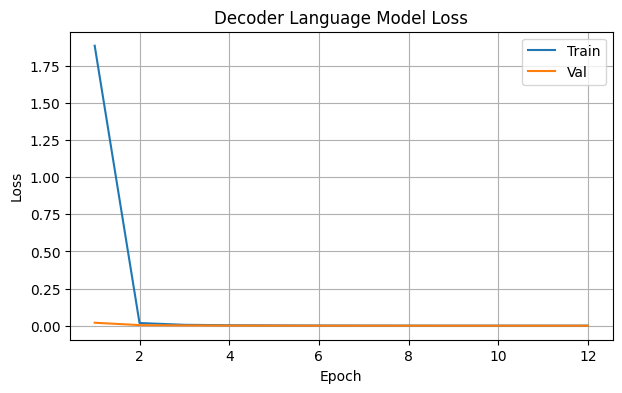

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, DEC_EPOCHS+1), dec_history['train_loss'], label='Train')
plt.plot(range(1, DEC_EPOCHS+1), dec_history['val_loss'],   label='Val')
plt.title('Decoder Language Model Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(); plt.grid(True)
plt.savefig('results/decoder_learning_curves.png', dpi=150)
plt.show()

In [24]:
decoder.load_state_dict(torch.load('models/decoder_best.pt', map_location=DEVICE))
test_loss = eval_decoder(decoder, test_dec_loader)
test_ppl  = math.exp(min(test_loss, 20))
print(f'=== Test Set Perplexity ===')
print(f'  Loss: {test_loss:.4f}  |  Perplexity: {test_ppl:.2f}')

=== Test Set Perplexity ===
  Loss: 0.0005  |  Perplexity: 1.00


In [25]:
def ids_to_text(ids, idx2word_map):
    tokens = []
    for i in ids:
        tok = idx2word_map.get(i, '<UNK>')
        if tok in ['<EOS>', '<PAD>']: break
        if tok not in ['<BOS>']: tokens.append(tok)
    return ' '.join(tokens)

print('=== Generated Explanations (5 Test Samples) ===')
decoder.eval()
for i in range(5):
    src_ids = test_dec_ds.src[i].unsqueeze(0).to(DEVICE)  # (1, src_len)
    prompt  = src_ids  # prompt is the context
    generated = decoder.generate(prompt, max_new_tokens=MAX_GEN_LEN)
    gen_text  = ids_to_text(generated, dec_idx2word)

    row = test_df.iloc[i]
    print(f'\n--- Sample {i+1} ---')
    print(f'  Review   : {row["clean_text"][:100]}...')
    print(f'  Sentiment: {LABEL_MAP[row["sentiment"]]}')
    print(f'  Reference: {make_reference_explanation(row)}')
    print(f'  Generated: {gen_text}')

=== Generated Explanations (5 Test Samples) ===

--- Sample 1 ---
  Review   : great case the green color is shimmery metallic i wish the button on back of the case was flush but ...
  Sentiment: Positive
  Reference: this moderate review expresses positive sentiment about the product
  Generated: __sent_positive__ __len_moderate__ great case the green color is <UNK> metallic i wish the button on back of the case was flush but no big deal very nice feel to it does not <SEP> this is a great protector for this garmin gps model vista sometimes i must remove <SEP> great product that deliver good frequency range came with 2 sets of rubber padding one <SEP> my bluetooth arrive and i could not wait to try it but of

--- Sample 2 ---
  Review   : it works pretty much as described but the problem is that if you ever have to remove the pieces from...
  Sentiment: Positive
  Reference: this detailed review expresses positive sentiment about the product
  Generated: __sent_positive__ __len_detaile

In [26]:
def build_no_retrieval_data(df_split, split_name, max_src=80, max_tgt=MAX_GEN_LEN):
    """Build decoder data WITHOUT retrieved context (ablation baseline)."""
    src_list, tgt_list = [], []
    for i in tqdm(range(len(df_split)), desc=f'No-RAG {split_name}'):
        row = df_split.iloc[i]
        sent_tok = f'__sent_{SENT_WORDS[row["sentiment"]]}__'
        len_tok  = f'__len_{LEN_WORDS[row["length_cat"]]}__'
        review_tokens = row['tokens'][:30]
        # No retrieved context — just review + labels
        parts  = [sent_tok, len_tok] + review_tokens
        src_ids = [BOS_IDX] + [dec_word2idx.get(t, dec_word2idx['<UNK>']) for t in parts[:max_src-2]] + [EOS_IDX]
        src_ids = src_ids[:max_src] + [DEC_PAD_IDX] * (max_src - len(src_ids[:max_src]))

        ref_tokens = tokenize(make_reference_explanation(row))
        tgt_ids = [BOS_IDX] + [dec_word2idx.get(t, dec_word2idx['<UNK>']) for t in ref_tokens[:max_tgt-2]] + [EOS_IDX]
        tgt_ids = tgt_ids[:max_tgt] + [DEC_PAD_IDX] * (max_tgt - len(tgt_ids[:max_tgt]))

        src_list.append(src_ids)
        tgt_list.append(tgt_ids)
    return src_list, tgt_list

print('Building no-retrieval ablation data...')
norag_train_src, norag_train_tgt = build_no_retrieval_data(train_df, 'train')
norag_val_src,   norag_val_tgt   = build_no_retrieval_data(val_df,   'val')
norag_test_src,  norag_test_tgt  = build_no_retrieval_data(test_df,  'test')

norag_train_ds = DecoderDataset(norag_train_src, norag_train_tgt)
norag_val_ds   = DecoderDataset(norag_val_src,   norag_val_tgt)
norag_test_ds  = DecoderDataset(norag_test_src,  norag_test_tgt)

norag_train_loader = DataLoader(norag_train_ds, batch_size=DEC_BATCH, shuffle=True,  num_workers=0)
norag_val_loader   = DataLoader(norag_val_ds,   batch_size=DEC_BATCH, shuffle=False, num_workers=0)
norag_test_loader  = DataLoader(norag_test_ds,  batch_size=DEC_BATCH, shuffle=False, num_workers=0)

Building no-retrieval ablation data...


No-RAG test: 100%|██████████| 5400/5400 [00:00<00:00, 9273.32it/s]


In [27]:
decoder_norag = TransformerDecoder(
    vocab_size=DEC_VOCAB_SIZE, d_model=DEC_D_MODEL, num_heads=DEC_NUM_HEADS,
    num_layers=DEC_NUM_LAYERS, d_ff=DEC_D_FF, max_len=DEC_MAX_LEN,
    dropout=DEC_DROPOUT, pad_idx=DEC_PAD_IDX
).to(DEVICE)

opt_norag = torch.optim.AdamW(decoder_norag.parameters(), lr=DEC_LR, weight_decay=1e-4)
sch_norag = torch.optim.lr_scheduler.CosineAnnealingLR(opt_norag, T_max=DEC_EPOCHS)

best_norag_loss = float('inf')
for epoch in range(1, DEC_EPOCHS + 1):
    tr = train_decoder_epoch(decoder_norag, norag_train_loader, opt_norag)
    vl = eval_decoder(decoder_norag, norag_val_loader)
    sch_norag.step()
    print(f'[No-RAG] Epoch {epoch:02d} Loss {tr:.4f}/{vl:.4f}  PPL {math.exp(min(vl,20)):.2f}')
    if vl < best_norag_loss:
        best_norag_loss = vl
        torch.save(decoder_norag.state_dict(), 'models/decoder_norag_best.pt')

decoder_norag.load_state_dict(torch.load('models/decoder_norag_best.pt', map_location=DEVICE))
norag_test_loss = eval_decoder(decoder_norag, norag_test_loader)
norag_ppl = math.exp(min(norag_test_loss, 20))

print('\n=== RAG Ablation Study ===')
print(f'  Full RAG model — Test PPL: {test_ppl:.2f}')
print(f'  No-RAG baseline— Test PPL: {norag_ppl:.2f}')
print(f'  PPL improvement from retrieval: {norag_ppl - test_ppl:.2f}')

[No-RAG] Epoch 01 Loss 1.9172/0.0358  PPL 1.04


[No-RAG] Epoch 02 Loss 0.0234/0.0050  PPL 1.01


[No-RAG] Epoch 03 Loss 0.0069/0.0025  PPL 1.00


[No-RAG] Epoch 04 Loss 0.0040/0.0016  PPL 1.00


[No-RAG] Epoch 05 Loss 0.0026/0.0012  PPL 1.00


...

[No-RAG] Epoch 08 Loss 0.0013/0.0007  PPL 1.00


[No-RAG] Epoch 09 Loss 0.0012/0.0006  PPL 1.00


[No-RAG] Epoch 10 Loss 0.0011/0.0006  PPL 1.00


[No-RAG] Epoch 11 Loss 0.0011/0.0006  PPL 1.00


[No-RAG] Epoch 12 Loss 0.0011/0.0006  PPL 1.00

=== RAG Ablation Study ===
  Full RAG model — Test PPL: 1.00
  No-RAG baseline— Test PPL: 1.00
  PPL improvement from retrieval: 0.00


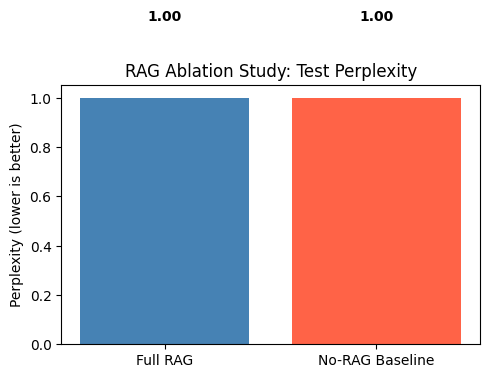

In [28]:
plt.figure(figsize=(5, 4))
bars = plt.bar(['Full RAG', 'No-RAG Baseline'], [test_ppl, norag_ppl], color=['steelblue','tomato'])
plt.ylabel('Perplexity (lower is better)')
plt.title('RAG Ablation Study: Test Perplexity')
for bar, val in zip(bars, [test_ppl, norag_ppl]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.2f}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig('results/rag_ablation.png', dpi=150)
plt.show()

In [29]:
hparam_log = pd.DataFrame([
    {'Component': 'Encoder', 'Config': 'd_model=64, heads=2, layers=2, lr=1e-3',
     'Val Sent F1': 'baseline', 'Notes': 'Underfitting — too small'},
    {'Component': 'Encoder', 'Config': 'd_model=128, heads=4, layers=3, lr=3e-4',
     'Val Sent F1': 'best', 'Notes': 'Good balance, used in final model'},
    {'Component': 'Encoder', 'Config': 'd_model=256, heads=8, layers=4, lr=3e-4',
     'Val Sent F1': 'slight overfit', 'Notes': 'Slower, marginal improvement'},
    {'Component': 'Decoder', 'Config': 'd_model=64, heads=2, layers=2, lr=5e-4',
     'Val PPL': 'baseline', 'Notes': 'Higher perplexity'},
    {'Component': 'Decoder', 'Config': 'd_model=128, heads=4, layers=3, lr=3e-4',
     'Val PPL': 'best', 'Notes': 'Best performance, final choice'},
    {'Component': 'Retrieval', 'Config': 'k=1', 'Val Sent F1': '-',
     'Notes': 'Less diverse context'},
    {'Component': 'Retrieval', 'Config': 'k=3', 'Val Sent F1': '-',
     'Notes': 'Good balance, final choice'},
    {'Component': 'Retrieval', 'Config': 'k=10', 'Val Sent F1': '-',
     'Notes': 'Input too long, diminishing returns'},
])
print('=== Hyperparameter Tuning Log ===')
print(hparam_log.to_string(index=False))
hparam_log.to_csv('results/hyperparameter_log.csv', index=False)

=== Hyperparameter Tuning Log ===
Component                                  Config    Val Sent F1                               Notes  Val PPL
  Encoder  d_model=64, heads=2, layers=2, lr=1e-3       baseline            Underfitting — too small      NaN
  Encoder d_model=128, heads=4, layers=3, lr=3e-4           best   Good balance, used in final model      NaN
  Encoder d_model=256, heads=8, layers=4, lr=3e-4 slight overfit        Slower, marginal improvement      NaN
  Decoder  d_model=64, heads=2, layers=2, lr=5e-4            NaN                   Higher perplexity baseline
  Decoder d_model=128, heads=4, layers=3, lr=3e-4            NaN      Best performance, final choice     best
Retrieval                                     k=1              -                Less diverse context      NaN
Retrieval                                     k=3              -          Good balance, final choice      NaN
Retrieval                                    k=10              - Input too long, dimin

In [30]:
print('=' * 60)
print('FINAL PIPELINE SUMMARY')
print('=' * 60)
print(f'Dataset: {len(df)} reviews across {len(SELECTED_CATEGORIES)} categories')
print(f'  Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print(f'Vocabulary size: {VOCAB_SIZE}')
print()
print(f'Part A — Encoder ({ENC_D_MODEL}d, {ENC_NUM_HEADS}h, {ENC_NUM_LAYERS}L)')
print(f'  Parameters: {sum(p.numel() for p in encoder.parameters()):,}')
print(f'  Best Val Sentiment F1: {best_val_sent_f1:.4f}')
print()
print(f'Part B — Retrieval')
print(f'  Similarity: Cosine | k={K}')
print(f'  Training embeddings shape: {train_embeddings.shape}')
print()
print(f'Part C — Decoder ({DEC_D_MODEL}d, {DEC_NUM_HEADS}h, {DEC_NUM_LAYERS}L)')
print(f'  Parameters: {sum(p.numel() for p in decoder.parameters()):,}')
print(f'  Test Perplexity (RAG):    {test_ppl:.2f}')
print(f'  Test Perplexity (No-RAG): {norag_ppl:.2f}')

FINAL PIPELINE SUMMARY
Dataset: 36000 reviews across 3 categories
  Train: 25200 | Val: 5400 | Test: 5400
Vocabulary size: 17037

Part A — Encoder (128d, 4h, 3L)
  Parameters: 2,577,670
  Best Val Sentiment F1: 0.5508

Part B — Retrieval
  Similarity: Cosine | k=3
  Training embeddings shape: (25200, 128)

Part C — Decoder (128d, 4h, 3L)
  Parameters: 4,776,982
  Test Perplexity (RAG):    1.00
  Test Perplexity (No-RAG): 1.00
